# Лабораторна робота 2

**Виконала:** Проніна Катерина Сергіївна

**Група:** КМ-51

**Датасет:** DS1 

## Мета роботи

Зчитати датасет (набір точок на площині) з текстового файлу та відобразити його у вікні (полотні) розміром 960×540 пкс, розмістивши початок координат (0; 0) у нижньому лівому куті з додатним напрямком осі Y угору та осі X управо. Зберегти результат у графічному форматі.

## Хід роботи

- Обрати індивідуальний датасет за посиланням - номер датасету відповідає останній цифрі логіну на платформі Сікорський **DS1**.
- Завантажити файл з датасетом. Файл у текстовому форматі містить пари цілих чисел, які є координатами точок.
- Дослідити структуру файлу та діапазони координат.
- Налаштувати полотно 960×540 пкс із початком координат у нижньому лівому куті.
- Відобразити точки за заданими координатами та зберегти результат у файл `DS1_plot.png`.

## Необхідно написати програму, яка:

1. Зчитує датасет з файлу;
2. Встановлює розміри вікна (полотна - canvas size) **960×540** пкс;
3. Відображає точки за заданими координатами вважаючи (0; 0) в нижньому лівому куті, позитивний напрямок Y - вгору, X - управо;
4. Виводить результат у графічний формат (PNG).

## Програма

### 1. Імпорт бібліотек

In [6]:
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image  # використовується лише для перевірки розміру збереженого зображення

### 2. Зчитування датасету

Кожен рядок файлу `DS1.txt` має вигляд `x y`. Функція `np.loadtxt` розбиває рядки за пробілами та повертає масив розміром `N × 2`.

In [7]:
data_file = Path("DS1.txt")
output_dir = Path(".")

points = np.loadtxt(data_file, dtype=int)  # кожен рядок файлу: "x y"
x, y = points[:, 0], points[:, 1]

print(f"Файл: {data_file}")
print(f"Кількість точок: {len(points)}")
print(f"X: від {x.min()} до {x.max()}")
print(f"Y: від {y.min()} до {y.max()}")
print("Перші 5 точок:")
print(points[:5])

Файл: DS1.txt
Кількість точок: 45915
X: від 174 до 746
Y: від 53 до 456
Перші 5 точок:
[[414  53]
 [415  53]
 [416  53]
 [417  53]
 [418  53]]


### 3. Параметри полотна

Розмір полотна - 960×540 пкс. Створюємо фігуру `figsize = (960/100, 540/100)` дюймів при `dpi = 100`, а область побудови (`axes`) розтягуємо на всю фігуру: `add_axes([0, 0, 1, 1])`. Межі осей задаємо рівними розмірам полотна (`xlim = 0…960`, `ylim = 0…540`), тому **1 одиниця координат = 1 піксель**. Вісь Y у matplotlib за замовчуванням спрямована вгору, а X - управо, початок координат (0; 0) знаходиться в нижньому лівому куті, як і вимагається.

In [8]:
CANVAS_W, CANVAS_H, DPI = 960, 540, 100

inside = (x >= 0) & (x < CANVAS_W) & (y >= 0) & (y < CANVAS_H)
print(f"Розмір полотна: {CANVAS_W} × {CANVAS_H} пкс")
print(f"Усі точки датасету вміщуються в полотно: {bool(inside.all())}")

Розмір полотна: 960 × 540 пкс
Усі точки датасету вміщуються в полотно: True


### 4. Відображення точок та збереження результату

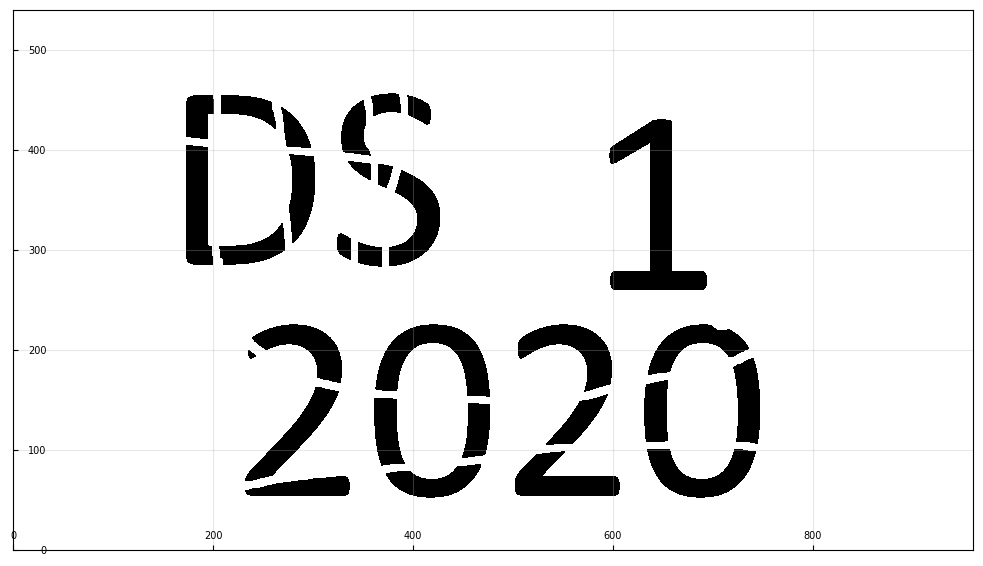

In [9]:
fig = plt.figure(figsize=(CANVAS_W / DPI, CANVAS_H / DPI), dpi=DPI)
ax = fig.add_axes([0, 0, 1, 1])          # область побудови займає все полотно

ax.set_xlim(0, CANVAS_W)                 # X: 0 ... 960 (управо)
ax.set_ylim(0, CANVAS_H)                 # Y: 0 ... 540 (угору), (0; 0) — нижній лівий кут

ax.scatter(x, y, s=1.5, c="black", marker="s", linewidths=0)

# допоміжна сітка та підписи осей всередині полотна — для орієнтації
ax.grid(True, alpha=0.3)
ax.tick_params(direction="in", labelsize=7)
ax.tick_params(axis="x", pad=-14)
ax.tick_params(axis="y", pad=-24)

fig.savefig(output_dir / "DS1_plot.png", dpi=DPI)
plt.show()

In [10]:
with Image.open(output_dir / "DS1_plot.png") as img:
    print(f"Збережено DS1_plot.png ({img.width} × {img.height} пкс).")

Збережено DS1_plot.png (960 × 540 пкс).
